## Evaluation of XAI Experiment

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats as st
import matplotlib.pyplot as plt
import scienceplots
plt.style.use(['science', 'no-latex'])

PATH_AB = './beexplainable/jspsych_experiment/beexplainable-groupsab.csv'

stats_ab = pd.read_csv(PATH_AB)

classes = np.array( ["Andrena bicolor", "Andrena flavipes", "Andrena fulva",
                     "Bombus lucorum", "Bombus pratorum"] )

num_samples_per_task = 10.0

In [2]:
# Split dataset in control and xai groups
users_a, users_b = [], []
user_ids = {'Control': [], 'XAI': []}

user_ids_ab = stats_ab.index[stats_ab['success'] == True].tolist()
user_ids_ab.append(len(stats_ab)) # Add last row index for consistency

for i in range(len(user_ids_ab)-1):
    # Current user's rows
    user = stats_ab.loc[user_ids_ab[i] : user_ids_ab[i+1]-1] # Select user rows by label indexes (start & end included)

    # Which group was this user part of?
    # Only XAI users saw the questionnaire
    if len( np.asarray(user.index[user['question_order'].isnull() == False]) ) > 0:
        users_b.append(user)
        user_ids['XAI'].append(user_ids_ab[i])
    else:
        users_a.append(user)
        user_ids['Control'].append(user_ids_ab[i])

stats = {'Control': pd.concat(users_a), 'XAI': pd.concat(users_b)}
# Users from Control Group have 68 rows, XAI Group has 69 (because of the questionnaire)
user_ids['Control'].append(user_ids['Control'][-1] + 68)
user_ids['XAI'].append(user_ids['XAI'][-1] + 69)

In [3]:
# Remove outliers (users that do not get more than 3 answers right in every task)
for group in ['Control', 'XAI']:

    num_rows = 68 if group == 'Control' else 69
    outlier_inds = []
    print(group + ' group before outlier removal: ' + str(len(user_ids[group])-1))

    for i in range(len(user_ids[group])-1):
        # Current user's rows
        user = stats[group].loc[user_ids[group][i] : user_ids[group][i+1]-1] # Select user rows by label indexes
        # Note: after removing outliers, these indexes will have gaps

        # Get rows for the different tasks
        user_task = {'Task_1': user[user['task'] == 'response_1'],
                     'Task_2': user[user['task'] == 'response_pred'],
                     'Task_3': user[user['task'] == 'response_2']}

        # Get current user's num. of correct responses and mark if outlier (any task has less than 4 correct)
        for task in user_task:
            if np.count_nonzero(user_task[task]['correct'] == True) < 4:
                outlier_inds.append(user_ids[group][i])
                break

    # List of outlier row indexes to remove
    outlier_ind_lists = []
    for i in range(len(user_ids[group])-1):
        if user_ids[group][i] in outlier_inds:
            outlier_ind_lists += list(range(user_ids[group][i],
                                            user_ids[group][i] + num_rows))
    stats[group].drop(outlier_ind_lists, inplace = True)

    # Remove outlier indexes
    for o in outlier_inds: user_ids[group].remove(o)
    print(group + ' group after outlier removal: ' + str(len(user_ids[group])-1))
    print('**********')

Control group before outlier removal: 43
Control group after outlier removal: 41
**********
XAI group before outlier removal: 37
XAI group after outlier removal: 34
**********


### Didactics Aspect

Does the XAI Group learn more from seeing explanations than the Control Group without seeing explanations?

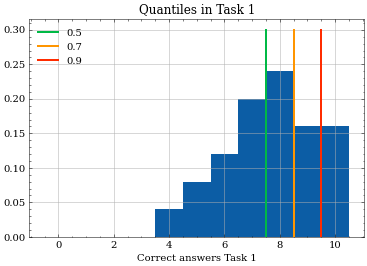

In [4]:
# Plot scores in Task 1 for both groups together
corrects_1 = []

for group in ['Control', 'XAI']:
    for i in range(len(user_ids[group])-1):
        # Current user's rows
        user = stats[group].loc[user_ids[group][i]:user_ids[group][i+1]-1] # Select rows by label indexes

        # Get rows for Task 1
        user_task_1 = user[user['task'] == 'response_1']

        # Append current user's score in Task 1
        corrects_1.append( np.count_nonzero(user_task_1['correct'] == True) )

# Compute various quantiles
qs = [0.5, 0.7, 0.9]
corrects_1_q = [np.quantile(corrects_1, q) for q in qs]

# Plot histogram of scores for all users in Task 1
plt.hist(corrects_1, bins = np.arange(num_samples_per_task+2)-0.5, density = True)
for cq in corrects_1_q:
    plt.plot([cq-0.5, cq-0.5], [0.0, 0.3], lw=2)
plt.xlabel('Correct answers Task 1')
plt.title('Quantiles in Task 1')
plt.legend(qs)
plt.grid()
plt.show()

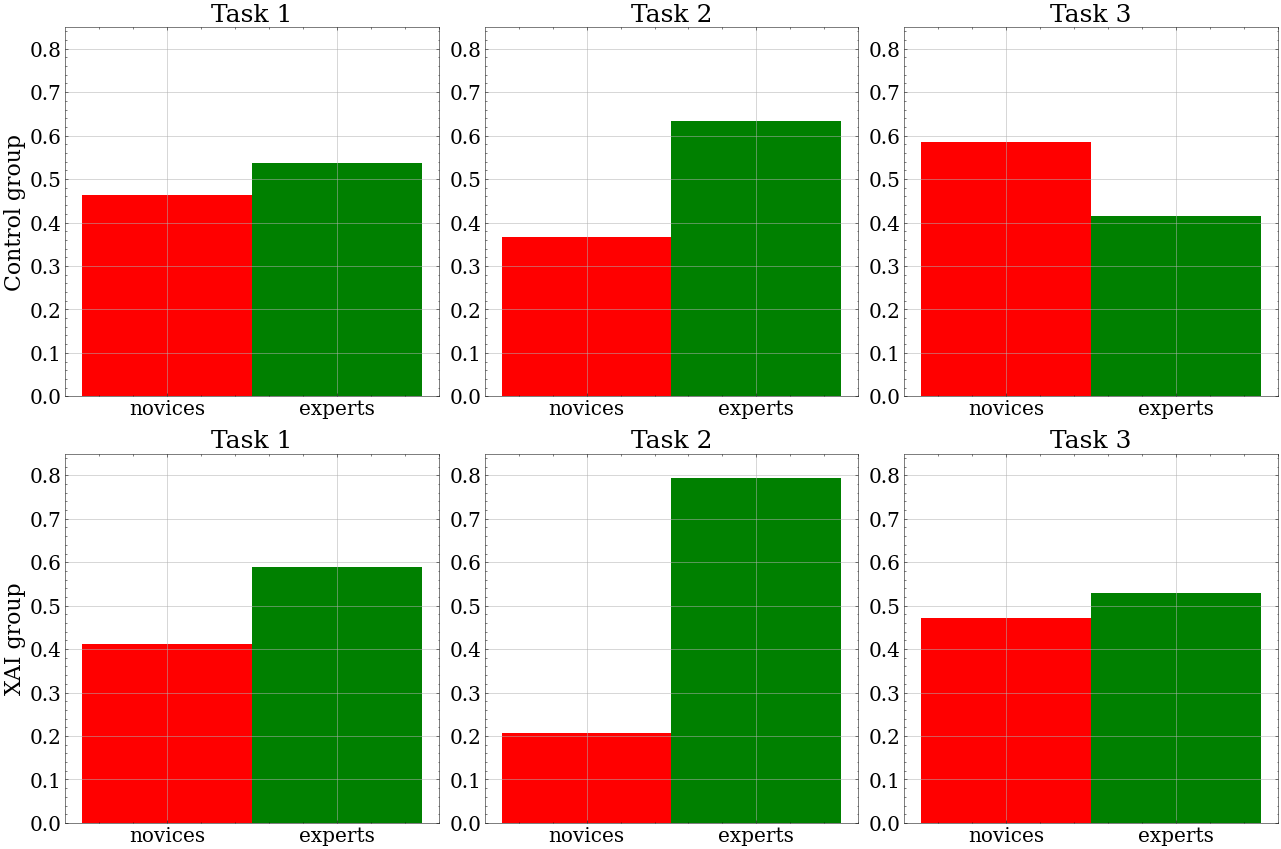

In [4]:
# Dictionaries of lists for numbers of correct responses per user per task per group
corrects = {'Task_1': {'Control': [], 'XAI': []},
            'Task_2': {'Control': [], 'XAI': []},
            'Task_3': {'Control': [], 'XAI': []}}
# Bin heights novices + experts in T2+3
bin_vals = {'Task_1': {'Control': {'novices': 0.0, 'experts': 0.0},
                       'XAI':     {'novices': 0.0, 'experts': 0.0}},
            'Task_2': {'Control': {'novices': 0.0, 'experts': 0.0},
                       'XAI':     {'novices': 0.0, 'experts': 0.0}},
            'Task_3': {'Control': {'novices': 0.0, 'experts': 0.0},
                       'XAI':     {'novices': 0.0, 'experts': 0.0}}}
j = 1 # counter for subplots
fontsize = 20
proficiency = True # if true, plot accuracies divided into novices and experts; otherwise, one bar per answer

plt.figure(figsize = (18,12))
for group in ['Control', 'XAI']:

    for i in range(len(user_ids[group])-1):
        # Current user's rows
        user = stats[group].loc[user_ids[group][i] : user_ids[group][i+1]-1] # Select rows by label indexes

        # Get rows for the different tasks
        user_task = {'Task_1': user[user['task'] == 'response_1'],
                     'Task_2': user[user['task'] == 'response_pred'],
                     'Task_3': user[user['task'] == 'response_2']}

        # Get current user's num. of correct responses
        for task in corrects:
            corrects[task][group].append( np.count_nonzero(user_task[task]['correct'] == True) )

    # Plot histograms
    for task in corrects:
        plt.subplot(2, 3, j)

        if proficiency:
            num_novices = np.count_nonzero(np.asarray(corrects[task][group]) < 8)
            nov_exp_ticks = ['novices'] * num_novices + ['experts'] * (len(user_ids[group])-1 - num_novices)
            n, _, patches = plt.hist(nov_exp_ticks, bins = np.arange(3)-0.5, density = True, color = 'red')
            bin_vals[task][group]['novices'], bin_vals[task][group]['experts'] = n[0], n[1]
            plt.setp(patches[1], 'facecolor', 'green')
            plt.ylim(0.0, 0.85)
        else:
            n, _, patches = plt.hist(corrects[task][group],
                                     bins = np.arange(4, num_samples_per_task+2)-0.5, density = True, color = 'red')
            bin_vals[task][group]['novices'], bin_vals[task][group]['experts'] = np.sum(n[-4::-1]), np.sum(n[-3:])
            plt.setp(patches[-3:], 'facecolor', 'green')
            plt.xlabel('Correct answers', fontsize=fontsize+2)
            plt.ylim(0.0, 0.45)

        plt.title(task.replace('_', ' '), fontsize=fontsize+5)
        if j % 3 == 1: plt.ylabel(group + ' group',  fontsize=fontsize+2)
        plt.xticks(fontsize=fontsize); plt.yticks(fontsize=fontsize)
        plt.grid()
        j += 1
plt.tight_layout()
#plt.savefig('./beexplainable/figures/jspsych/didactics_3.png')
plt.show()

In [7]:
bin_vals

{'Task_1': {'Control': {'novices': 0.4634146341463415,
   'experts': 0.5365853658536586},
  'XAI': {'novices': 0.4117647058823529, 'experts': 0.5882352941176471}},
 'Task_2': {'Control': {'novices': 0.36585365853658536,
   'experts': 0.6341463414634146},
  'XAI': {'novices': 0.20588235294117646, 'experts': 0.7941176470588235}},
 'Task_3': {'Control': {'novices': 0.5853658536585366,
   'experts': 0.4146341463414634},
  'XAI': {'novices': 0.47058823529411764, 'experts': 0.5294117647058824}}}

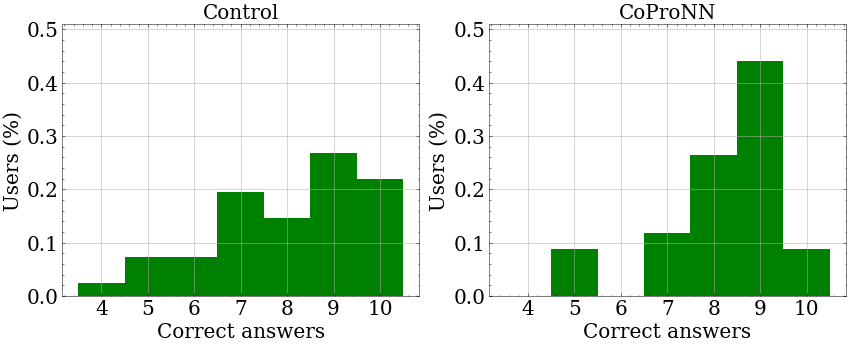

In [5]:
# Extra plot just to compare Task 2 performances (for CoProNN paper)
fontsize = 20
plt.figure(figsize = (12,5))
for i, group in enumerate(list(stats.keys())):
    plt.subplot(1, 2, i+1)
    n, _, patches = plt.hist(corrects['Task_2'][group],
                             bins = np.arange(4, num_samples_per_task+2)-0.5,
                             density = True, color = 'green')
    #bin_vals[task][group]['novices'], bin_vals[task][group]['experts'] = np.sum(n[-4::-1]), np.sum(n[-3:])
    if i == 0: plt.title('Control', fontsize=fontsize)
    else: plt.title('CoProNN', fontsize=fontsize)
    plt.xlabel('Correct answers', fontsize=fontsize)
    plt.ylabel('Users (%)', fontsize=fontsize)
    plt.ylim(0.0, 0.51)
    plt.xticks(fontsize=fontsize)
    plt.yticks(np.arange(0.0, 0.51, 0.1), fontsize=fontsize)
    plt.grid()
plt.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/task_2_corrects.png')
plt.show()

In [26]:
print('*** Task 2 ***')
for group in list(stats.keys()):
    print(group)
    print('Mean: ' + str(np.round( np.mean(corrects['Task_2'][group]), 2 )))
    print('Std.: ' + str(np.round( np.std(corrects['Task_2'][group]), 2 )))
    print('Median: ' + str(np.median(corrects['Task_2'][group])) + '\n')

*** Task 2 ***
Control
Mean: 8.05
Std.: 1.64
Median: 8.0

XAI
Mean: 8.24
Std.: 1.28
Median: 9.0



### Trust Aspect

Does the XAI Group identify the wrong predictions (when seeing the wrong explanations) in Task 2 more often than the Control Group without these explanations?

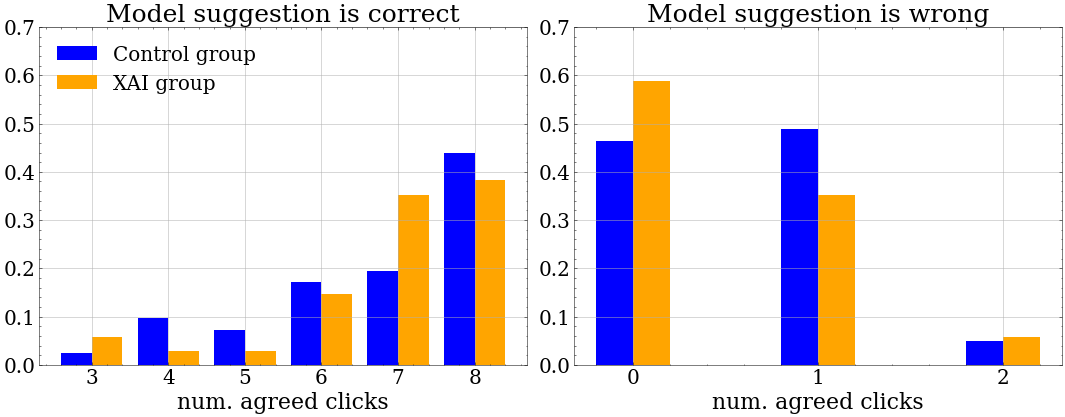

In [9]:
# Dictionary for num. of agreements on Task 2 for every user
agrees = {'Control': {'conno': [], 'conok': []}, 'XAI': {'conno': [], 'conok': []}}
num_wrong_samples = 2.0 # num. of wrongly predicted samples shown in Task 2
bar_w = 0.4
colors = ['blue', 'orange']
fontsize = 20

plt.figure(figsize = (15, 6))
for j, group in enumerate(['Control', 'XAI']):

    for i in range(len(user_ids[group])-1):
        # Current user's rows
        user = stats[group].loc[user_ids[group][i] : user_ids[group][i+1]-1] # Select user rows by label indexes

        # Get rows for the different tasks
        user_task_2 = user[user['task'] == 'response_pred']

        # Differentiate between samples where the model predicted the concepts correctly vs not
        user_task_2_conno = user_task_2[user_task_2['correct_response'] != user_task_2['pred_class']]
        user_task_2_conok = user_task_2[user_task_2['correct_response'] == user_task_2['pred_class']]

        # Get current user's num. responses agreeing with the model's class prediction
        responses = np.asarray(user_task_2_conno['response'], dtype=np.uint8)
        agrees[group]['conno'].append( np.count_nonzero(classes[responses] == user_task_2_conno['pred_class']) )
        responses = np.asarray(user_task_2_conok['response'], dtype=np.uint8)
        agrees[group]['conok'].append( np.count_nonzero(classes[responses] == user_task_2_conok['pred_class']) )

    # Plot histograms
    plt.subplot(1, 2, 1)
    answers, counts = np.unique(agrees[group]['conok'], return_counts=True)
    counts_rel = tuple(counts/len(agrees[group]['conok']))
    plt.bar(np.arange(3, num_samples_per_task-num_wrong_samples+1)+j*bar_w-bar_w/2,
            counts_rel,
            bar_w, label = group + ' group', color = colors[j])
    plt.xlabel('num. agreed clicks', fontsize=fontsize+2)
    plt.xticks(fontsize=fontsize); plt.yticks(fontsize=fontsize)
    plt.ylim(0.0, 0.7)
    plt.title('Model suggestion is correct', fontsize=fontsize+5)
    plt.legend(loc = 'upper left', fontsize=fontsize)
    plt.grid(True)

    plt.subplot(1, 2, 2)
    answers, counts = np.unique(agrees[group]['conno'], return_counts=True)
    counts_rel = tuple(counts/len(agrees[group]['conno']))
    plt.bar(np.arange(3)+j*bar_w/2-bar_w/4,
            counts_rel,
            bar_w/2, label = group + ' group', color = colors[j])
    plt.xlabel('num. agreed clicks', fontsize=fontsize+2)
    plt.xticks([0, 1, 2], fontsize=fontsize); plt.yticks(fontsize=fontsize)
    plt.ylim(0.0, 0.7)
    plt.title('Model suggestion is wrong', fontsize=fontsize+5)
    plt.grid(True)

plt.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/confidence_all_fusion.png')
plt.show()

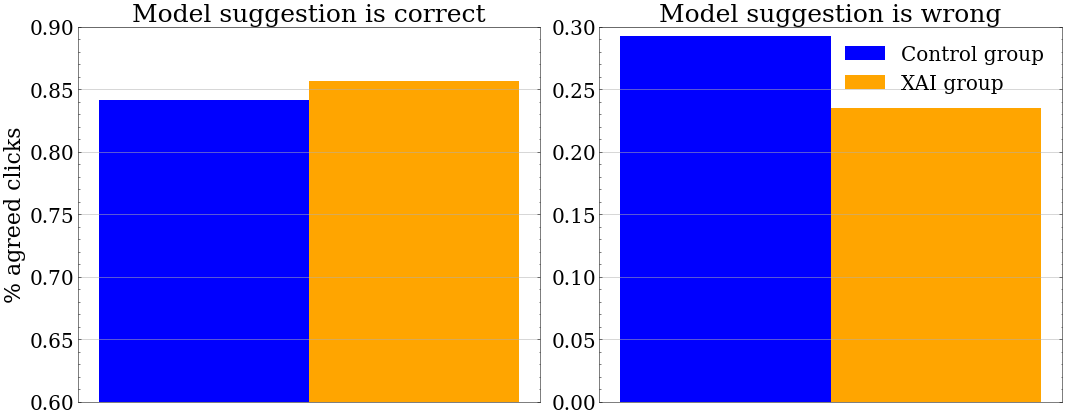

In [6]:
# Dictionary for num. of agreements on Task 2 for every user
agrees = {'Control': {'conno': [], 'conok': []}, 'XAI': {'conno': [], 'conok': []}}
num_wrong_samples = 2.0 # num. of wrongly predicted samples shown in Task 2
bar_w, bin_heights = 0.4, []
colors = ['blue', 'orange']
fontsize = 20

plt.figure(figsize = (15, 6))
for j, group in enumerate(['Control', 'XAI']):

    for i in range(len(user_ids[group])-1):
        # Current user's rows
        user = stats[group].loc[user_ids[group][i] : user_ids[group][i+1]-1] # Select user rows by label indexes

        # Get rows for the different tasks
        user_task_2 = user[user['task'] == 'response_pred']

        # Differentiate between samples where the model predicted the concepts correctly vs not
        user_task_2_conno = user_task_2[user_task_2['correct_response'] != user_task_2['pred_class']]
        user_task_2_conok = user_task_2[user_task_2['correct_response'] == user_task_2['pred_class']]

        # Get current user's num. responses agreeing with the model's class prediction
        responses = np.asarray(user_task_2_conno['response'], dtype=np.uint8)
        agrees[group]['conno'].append( np.count_nonzero(classes[responses] == user_task_2_conno['pred_class']) )
        responses = np.asarray(user_task_2_conok['response'], dtype=np.uint8)
        agrees[group]['conok'].append( np.count_nonzero(classes[responses] == user_task_2_conok['pred_class']) )

    # Plot histograms
    plt.subplot(1, 2, 1)
    n = np.sum(agrees[group]['conok']) / (8*len(agrees[group]['conok']))
    bin_heights.append(n)
    plt.bar(np.arange(1)+j*bar_w/2-bar_w/4, n,
            bar_w/2, label = group + ' group', color = colors[j])
    plt.ylabel('% agreed clicks', fontsize=fontsize+2)
    plt.xticks([]); plt.yticks(fontsize=fontsize)
    plt.ylim(0.6, 0.9)
    plt.title('Model suggestion is correct', fontsize=fontsize+5)
    plt.grid(True)

    plt.subplot(1, 2, 2)
    n = np.sum(agrees[group]['conno']) / (2*len(agrees[group]['conno']))
    bin_heights.append(n)
    plt.bar(np.arange(1)+j*bar_w/2-bar_w/4, n,
            bar_w/2, label = group + ' group', color = colors[j])
    plt.xticks([]); plt.yticks(fontsize=fontsize)
    plt.ylim(0.0, 0.3)
    plt.title('Model suggestion is wrong', fontsize=fontsize+5)
    plt.legend(loc = 'upper right', fontsize=fontsize)
    plt.grid(True)

plt.tight_layout()
#plt.savefig('./beexplainable/figures/jspsych/confidence_all_fusion_cumulative.png')
plt.show()

In [40]:
print('When the model was right:')
print('Control Group agreed with ' + str(np.round( bin_heights[0]*100, 2 )) + '% of the suggestions.')
print('XAI     Group agreed with ' + str(np.round( bin_heights[2]*100, 2 )) + '% of the suggestions.')
print('\nWhen the model was wrong:')
print('Control Group agreed with ' + str(np.round( bin_heights[1]*100, 2 )) + '% of the suggestions.')
print('XAI     Group agreed with ' + str(np.round( bin_heights[3]*100, 2 )) + '% of the suggestions.')

When the model was right:
Control Group agreed with 84.15% of the suggestions.
XAI     Group agreed with 85.66% of the suggestions.

When the model was wrong:
Control Group agreed with 29.27% of the suggestions.
XAI     Group agreed with 23.53% of the suggestions.


In [7]:
df_agrees_dict = {'group': [], 'model suggestion': [], 'num. agreed clicks': []}
for group in ['Control', 'XAI']:
    for sugg in ['conok', 'conno']:
        df_agrees_dict['num. agreed clicks'] += agrees[group][sugg]
        df_agrees_dict['group'] += [group] * len(agrees[group][sugg])
        df_agrees_dict['model suggestion'] += ['correct' if sugg == 'conok' else 'wrong'] * len(agrees[group][sugg])
df_agrees = pd.DataFrame(data=df_agrees_dict)
#df_agrees

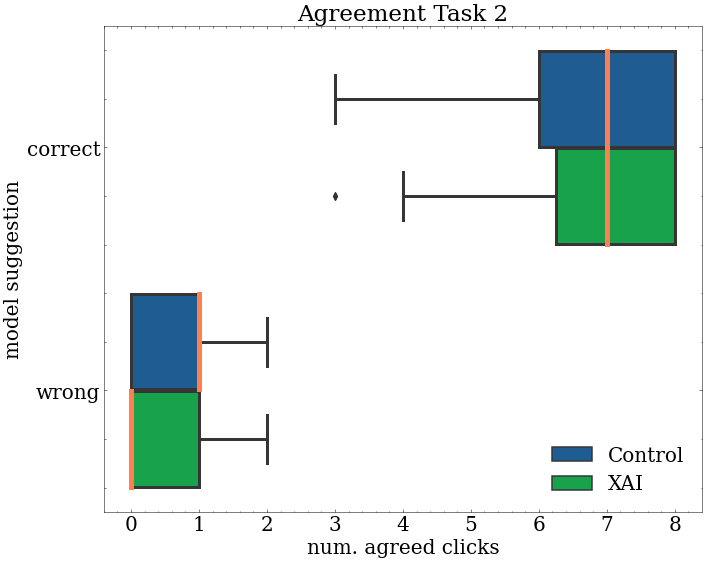

In [6]:
plt.figure(figsize=(10,8))
sns.boxplot(data=df_agrees, x='num. agreed clicks', y='model suggestion', hue='group', linewidth=3,
            medianprops={"color": "coral", "linewidth": 5});
plt.xticks(fontsize=fontsize);plt.yticks(fontsize=fontsize);
plt.xlabel('num. agreed clicks', fontsize=fontsize);plt.ylabel('model suggestion', fontsize=fontsize);
plt.legend(fontsize=fontsize, loc='lower right')
plt.title('Agreement Task 2', fontsize=fontsize+3)
plt.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/confidence_all_fusion_boxplots.png')
plt.show()

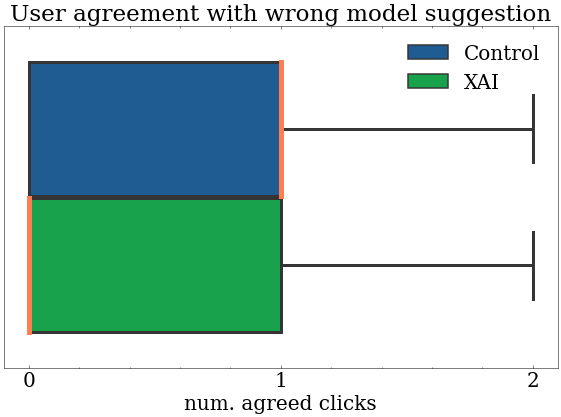

In [34]:
fig = plt.figure(figsize=(8, 6))
sns.boxplot(data=df_agrees[ df_agrees['model suggestion'] == 'wrong' ], x='num. agreed clicks', y='model suggestion', hue='group', linewidth=3,
            medianprops={"color": "coral", "linewidth": 5});
plt.xticks([0, 1, 2], fontsize=fontsize);plt.yticks([]);
plt.xlabel('num. agreed clicks', fontsize=fontsize);plt.ylabel('');
plt.legend(fontsize=fontsize, loc='upper right')
plt.title('User agreement with wrong model suggestion', fontsize=fontsize+3)
plt.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/confidence_all_fusion_boxplots_wrong.png')
plt.show()

In [9]:
# Get avg. clicks
avg_clicks_control = df_agrees.loc[(df_agrees['model suggestion'] == 'wrong') & (df_agrees['group'] == 'Control'), 'num. agreed clicks'].mean()
avg_clicks_xai     = df_agrees.loc[(df_agrees['model suggestion'] == 'wrong') & (df_agrees['group'] == 'XAI'),     'num. agreed clicks'].mean()
std_clicks_control = df_agrees.loc[(df_agrees['model suggestion'] == 'wrong') & (df_agrees['group'] == 'Control'), 'num. agreed clicks'].std()
std_clicks_xai     = df_agrees.loc[(df_agrees['model suggestion'] == 'wrong') & (df_agrees['group'] == 'XAI'),     'num. agreed clicks'].std()
print('Average agreed clicks:')
print('Control: ' + str(np.round(avg_clicks_control, 2)) + ' +/- ' + str(np.round(std_clicks_control, 2)))
print('XAI:     ' + str(np.round(avg_clicks_xai, 2))     + ' +/- ' + str(np.round(std_clicks_xai, 2)))

Average agreed clicks:
Control: 0.59 +/- 0.59
XAI:     0.47 +/- 0.61


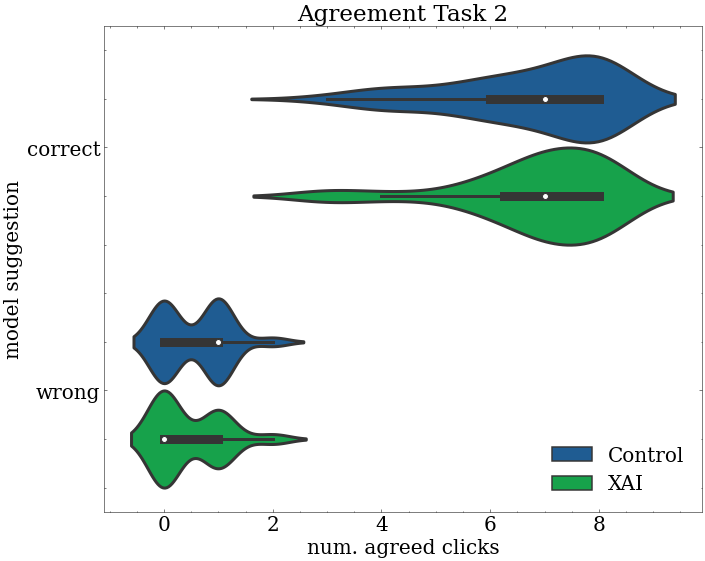

In [7]:
plt.figure(figsize=(10,8))
sns.violinplot(data=df_agrees, x='num. agreed clicks', y='model suggestion', hue='group', linewidth=3)
plt.xticks(fontsize=fontsize);plt.yticks(fontsize=fontsize);
plt.xlabel('num. agreed clicks', fontsize=fontsize);plt.ylabel('model suggestion', fontsize=fontsize);
plt.legend(fontsize=fontsize, loc='lower right')
plt.title('Agreement Task 2', fontsize=fontsize+3)
plt.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/confidence_all_fusion_violinplots.png')
plt.show()

#### Experts

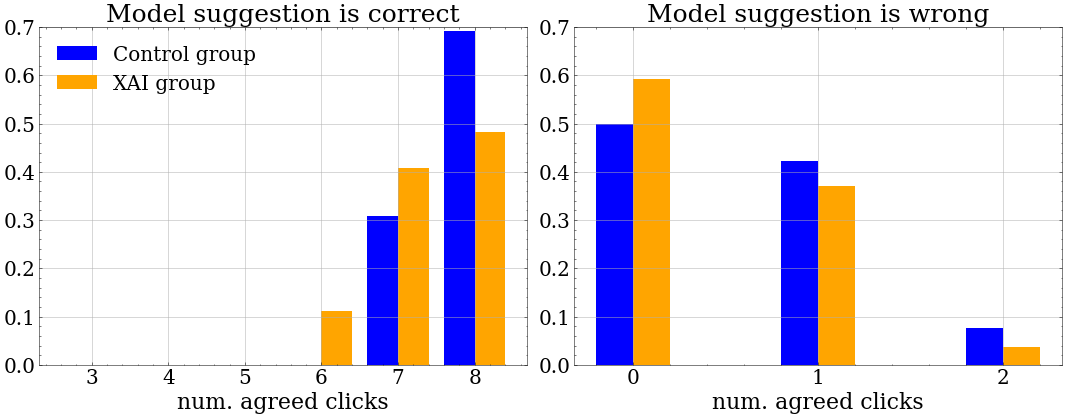

In [9]:
# Dictionary for num. of agreements on Task 2 for every user
agrees = {'Control': {'conno': [], 'conok': []}, 'XAI': {'conno': [], 'conok': []}}
num_wrong_samples = 2.0 # num. of wrongly predicted samples shown in Task 2
bar_w = 0.4
colors = ['blue', 'orange']
fontsize = 20

plt.figure(figsize = (15, 6))
for j, group in enumerate(['Control', 'XAI']):

    for i in range(len(user_ids[group])-1):
        # Current user's rows
        user = stats[group].loc[user_ids[group][i] : user_ids[group][i+1]-1] # Select user rows by label indexes

        # Only select Task 2 experts
        if np.count_nonzero(user[user['task'] == 'response_pred']['correct'] == True) >= 8:
            # Get rows for the different tasks
            user_task_2 = user[user['task'] == 'response_pred']

            # Differentiate between samples where the model predicted the concepts correctly vs not
            user_task_2_conno = user_task_2[user_task_2['correct_response'] != user_task_2['pred_class']]
            user_task_2_conok = user_task_2[user_task_2['correct_response'] == user_task_2['pred_class']]

            # Get current user's num. responses agreeing with the model's class prediction
            responses = np.asarray(user_task_2_conno['response'], dtype=np.uint8)
            agrees[group]['conno'].append( np.count_nonzero(classes[responses] == user_task_2_conno['pred_class']) )
            responses = np.asarray(user_task_2_conok['response'], dtype=np.uint8)
            agrees[group]['conok'].append( np.count_nonzero(classes[responses] == user_task_2_conok['pred_class']) )

    # Plot histograms
    plt.subplot(1, 2, 1)
    answers, counts = np.unique(agrees[group]['conok'], return_counts=True)
    counts_extended = np.zeros(6)
    for a in np.arange(3, int(num_samples_per_task-num_wrong_samples+1)): # fill in the zero counts
        if a in answers:
            counts_extended[a-3] = counts[np.where(answers==a)]
    counts_rel = tuple(counts_extended/len(agrees[group]['conok']))
    plt.bar(np.arange(3, num_samples_per_task-num_wrong_samples+1)+j*bar_w-bar_w/2,
            counts_rel,
            bar_w, label = group + ' group', color = colors[j])
    plt.xlabel('num. agreed clicks', fontsize=fontsize+2)
    plt.xticks(fontsize=fontsize); plt.yticks(fontsize=fontsize)
    plt.ylim(0.0, 0.7)
    plt.title('Model suggestion is correct', fontsize=fontsize+5)
    plt.legend(loc = 'upper left', fontsize=fontsize)
    plt.grid(True)

    plt.subplot(1, 2, 2)
    answers, counts = np.unique(agrees[group]['conno'], return_counts=True)
    counts_rel = tuple(counts/len(agrees[group]['conno']))
    plt.bar(np.arange(3)+j*bar_w/2-bar_w/4,
            counts_rel,
            bar_w/2, label = group + ' group', color = colors[j])
    plt.xlabel('num. agreed clicks', fontsize=fontsize+2)
    plt.xticks([0, 1, 2], fontsize=fontsize); plt.yticks(fontsize=fontsize)
    plt.ylim(0.0, 0.7)
    plt.title('Model suggestion is wrong', fontsize=fontsize+5)
    plt.grid(True)

plt.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/confidence_experts_fusion.png')
plt.show()

#### Novices

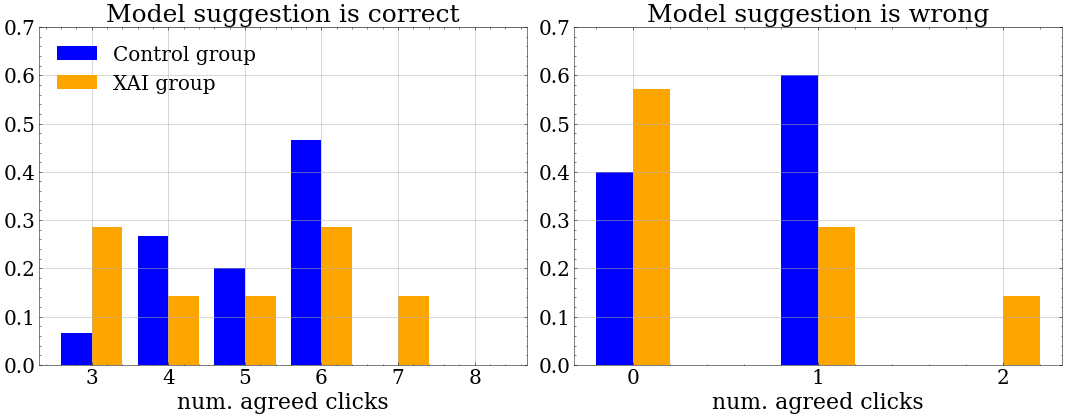

In [23]:
# Dictionary for num. of agreements on Task 2 for every user
agrees = {'Control': {'conno': [], 'conok': []}, 'XAI': {'conno': [], 'conok': []}}
num_wrong_samples = 2.0 # num. of wrongly predicted samples shown in Task 2
num_correct_samples = num_samples_per_task-num_wrong_samples
bar_w = 0.4
colors = ['blue', 'orange']
fontsize = 20

plt.figure(figsize = (15, 6))
for j, group in enumerate(['Control', 'XAI']):

    for i in range(len(user_ids[group])-1):
        # Current user's rows
        user = stats[group].loc[user_ids[group][i] : user_ids[group][i+1]-1] # Select user rows by label indexes

        # Only select Task 2 novices
        if np.count_nonzero(user[user['task'] == 'response_pred']['correct'] == True) < 8:
            # Get rows for the different tasks
            user_task_2 = user[user['task'] == 'response_pred']

            # Differentiate between samples where the model predicted the concepts correctly vs not
            user_task_2_conno = user_task_2[user_task_2['correct_response'] != user_task_2['pred_class']]
            user_task_2_conok = user_task_2[user_task_2['correct_response'] == user_task_2['pred_class']]

            # Get current user's num. responses agreeing with the model's class prediction
            responses = np.asarray(user_task_2_conno['response'], dtype=np.uint8)
            agrees[group]['conno'].append( np.count_nonzero(classes[responses] == user_task_2_conno['pred_class']) )
            responses = np.asarray(user_task_2_conok['response'], dtype=np.uint8)
            agrees[group]['conok'].append( np.count_nonzero(classes[responses] == user_task_2_conok['pred_class']) )

    # Plot histograms
    # Note: there may be missing values at the end of the sequences - manually add 0 for those
    plt.subplot(1, 2, 1)
    answers, counts = np.unique(agrees[group]['conok'], return_counts=True)
    if len(counts) < num_correct_samples-2: # minus 2, because there is a minimum of 3 agreed clicks for all users
        counts = np.append(counts, [0.0]*int(num_correct_samples-2-len(counts))) # append zero(s) for the missing answers
    counts_rel = tuple(counts/len(agrees[group]['conok']))
    plt.bar(np.arange(3, num_samples_per_task-num_wrong_samples+1)+j*bar_w-bar_w/2,
            counts_rel,
            bar_w, label = group + ' group', color = colors[j])
    plt.xlabel('num. agreed clicks', fontsize=fontsize+2)
    plt.xticks(fontsize=fontsize); plt.yticks(fontsize=fontsize)
    plt.ylim(0.0, 0.7)
    plt.title('Model suggestion is correct', fontsize=fontsize+5)
    plt.legend(loc = 'upper left', fontsize=fontsize)
    plt.grid(True)

    plt.subplot(1, 2, 2)
    answers, counts = np.unique(agrees[group]['conno'], return_counts=True)
    if len(counts) < num_wrong_samples+1: # plus 1, because 0 agreed clicks is also valid here
        counts = np.append(counts, [0.0]*int(num_wrong_samples+1-len(counts))) # append zero(s) for the missing answers
    counts_rel = tuple(counts/len(agrees[group]['conno']))
    plt.bar(np.arange(3)+j*bar_w/2-bar_w/4,
            counts_rel,
            bar_w/2, label = group + ' group', color = colors[j])
    plt.xlabel('num. agreed clicks', fontsize=fontsize+2)
    plt.xticks([0, 1, 2], fontsize=fontsize); plt.yticks(fontsize=fontsize)
    plt.ylim(0.0, 0.7)
    plt.title('Model suggestion is wrong', fontsize=fontsize+5)
    plt.grid(True)

plt.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/confidence_novices_fusion.png')
plt.show()

### Questionnaire Responses XAI Group

In [36]:
quest_responses = {"support_exp":    [],
                   "causal_exp":     [],
                   "know_exp":       [],
                   "understand_exp": []}
responses = ['strongly disagree', 'somewhat disagree', 'neutral',
             'somewhat agree', 'strongly agree']
colors    = ['red', 'pink', 'purple', 'olive', 'green']
titles = ['I did not need support\nto understand the model\'s explanations',
          'I found the model\'s explanations\nhelped me to understand causality',
          'I was able to use\nthe model\'s explanations with my knowledge base',
          'I think that most people would learn\nto understand the model\'s explanations very quickly']

for r in stats['XAI']['response']:
    if type(r) is str and len(r) > 10: # Questionnaire responses are stored in the longest string
        q_answers = r[1:-1].split(',') # Remove curly brackets and split pairs of question_type:responses separated by commas
        for qa in q_answers:
            curr_qa = qa.split(':') # Split question:answer pair
            # Append response index to corresponding q. entry (without quotes)
            quest_responses[ curr_qa[0][1:-1] ].append( responses.index(curr_qa[1][1:-1]) )

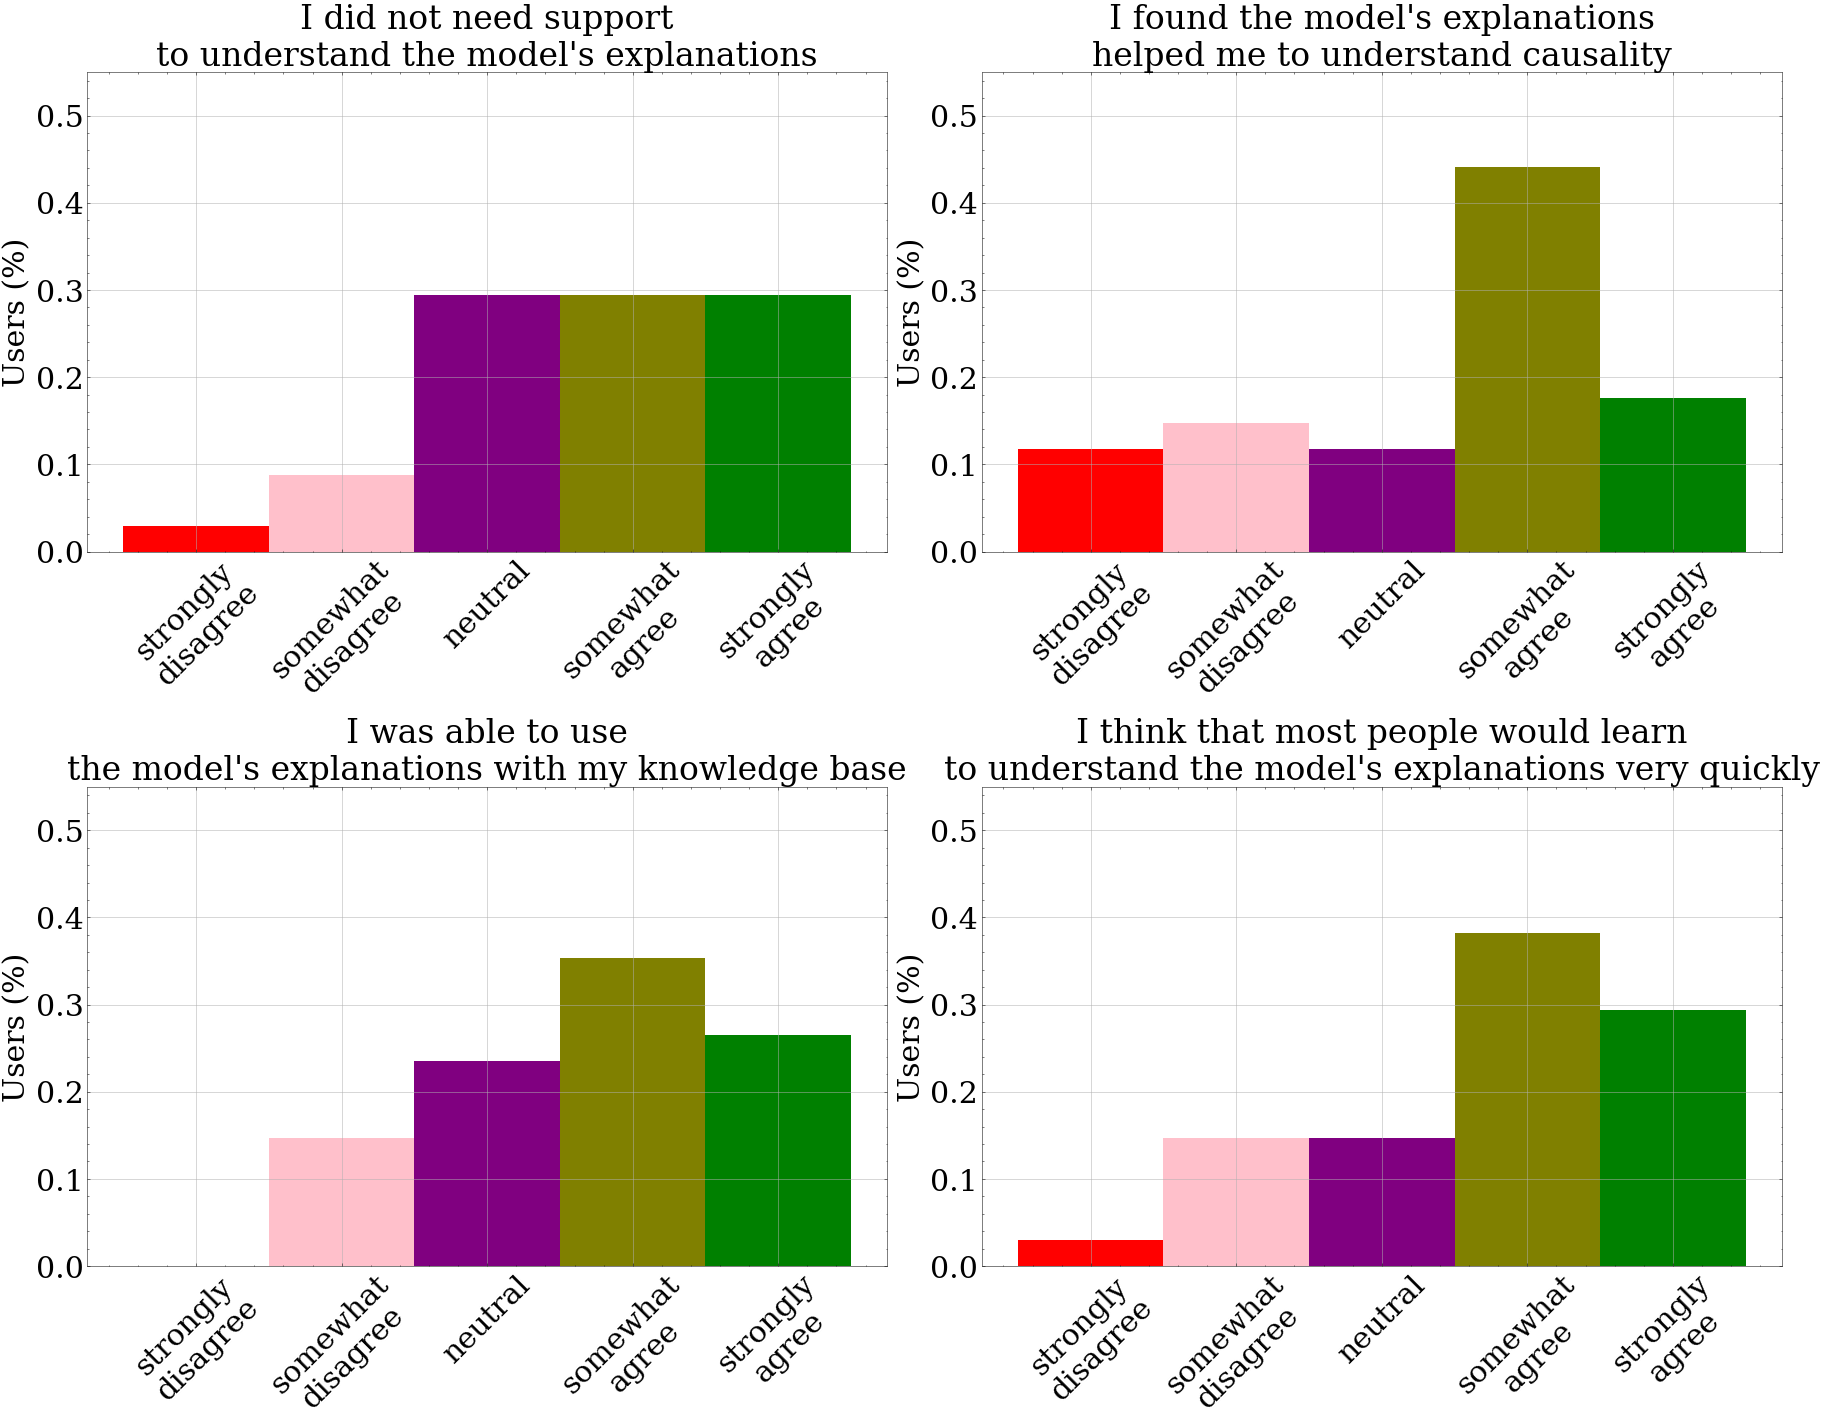

In [37]:
fontsize=30
fig = plt.figure(figsize=(25, 20))
for i, q in enumerate(quest_responses):
    plt.subplot(2, 2, i+1)
    _, _, patches = plt.hist(quest_responses[q], density = True, bins = np.arange(6)-0.5)
    for j in range(len(responses)):
        patches[j].set_facecolor(colors[j])
    plt.title(titles[i], fontsize=fontsize+3)
    plt.xticks(ticks = np.arange(5),
               labels = [r.replace(' ', '\n') for r in responses],
               rotation = 45, fontsize=fontsize)
    plt.yticks(fontsize=fontsize); plt.ylabel('Users (%)', fontsize=fontsize)
    plt.ylim(0.0, 0.55)
    plt.grid()
fig.tight_layout()
plt.savefig('./beexplainable/figures/jspsych/survey.png')
plt.show()

In [56]:
print('No support needed to understand explanations:')
p = np.count_nonzero(np.asarray(quest_responses['support_exp']) >= 3)/len(quest_responses['support_exp'])
p = np.round(p, 4)*100
print(str(p) + '% agree.')

No support needed to understand explanations:
58.81999999999999% agree.


In [57]:
print('Could understand causality:')
p = np.count_nonzero(np.asarray(quest_responses['causal_exp']) >= 3)/len(quest_responses['causal_exp'])
p = np.round(p, 4)*100
print(str(p) + '% agree.')
p = np.count_nonzero(np.asarray(quest_responses['causal_exp']) < 2)/len(quest_responses['causal_exp'])
p = np.round(p, 4)*100
print(str(p) + '% disagree.')

Could understand causality:
61.760000000000005% agree.
26.47% disagree.


In [58]:
print('Used explanations with own knowledge base:')
p = np.count_nonzero(np.asarray(quest_responses['know_exp']) >= 3)/len(quest_responses['know_exp'])
p = np.round(p, 4)*100
print(str(p) + '% agree.')

Used explanations with own knowledge base:
61.760000000000005% agree.


In [59]:
print('Most people could learn to understand the explanations very quickly:')
p = np.count_nonzero(np.asarray(quest_responses['understand_exp']) >= 3)/len(quest_responses['understand_exp'])
p = np.round(p, 4)*100
print(str(p) + '% agree.')

Most people could learn to understand the explanations very quickly:
67.65% agree.


### Uncertainties

In [4]:
# Get user uncertainties per sample per task
### For Task 2

# Load class predictions for every pool sample
softmax_preds = np.load("./beexplainable/metafiles/Bees/masked/pool_jspsych/softmax_preds.npy")
softmax_preds

array([[9.99999762e-01, 1.18658008e-08, 2.03315736e-07, 1.84052986e-08,
        9.28517208e-10],
       [8.41614246e-01, 3.71421464e-02, 1.06535815e-01, 1.46340327e-02,
        7.38696108e-05],
       [9.99566615e-01, 4.24170634e-04, 4.92835994e-08, 9.16117733e-06,
        4.52778837e-09],
       [9.99998689e-01, 1.25185568e-06, 8.46068937e-10, 1.87204190e-08,
        2.10073408e-12],
       [9.99991894e-01, 1.08725907e-07, 7.93155959e-06, 4.78870543e-09,
        3.81964932e-10],
       [9.99999762e-01, 7.33487215e-10, 2.63511907e-07, 2.84446466e-09,
        8.79199713e-10],
       [9.99998331e-01, 1.60526918e-06, 1.04435784e-07, 7.46174944e-09,
        2.11133222e-10],
       [9.99987125e-01, 4.15991462e-06, 1.30051649e-06, 7.39710322e-06,
        1.11779803e-08],
       [8.31917103e-04, 9.98450041e-01, 7.07936531e-04, 9.73519491e-06,
        4.11622267e-07],
       [9.99999166e-01, 8.60050989e-07, 1.51238453e-08, 1.61719420e-08,
        4.99654762e-10],
       [9.99988794e-01, 8.8915

In [5]:
# Read file names of all the pool samples
from beexplainable.beexplainable.utils import metafile_readers as mr
img_dict = mr.metafile_to_dict("./beexplainable/metafiles/Bees/masked/pool_jspsych/images.txt")
file_names = [val.split('/')[1] for val in img_dict.values() ]

img_softmax_dict = dict(zip(file_names, softmax_preds))
img_softmax_dict

{'Andrena_bicolor_2799379_1.jpg': array([9.9999976e-01, 1.1865801e-08, 2.0331574e-07, 1.8405299e-08,
        9.2851721e-10], dtype=float32),
 'Andrena_bicolor_39411385_1.jpg': array([8.41614246e-01, 3.71421464e-02, 1.06535815e-01, 1.46340327e-02,
        7.38696108e-05], dtype=float32),
 'Andrena_bicolor_39748872_3.jpg': array([9.9956661e-01, 4.2417063e-04, 4.9283599e-08, 9.1611773e-06,
        4.5277884e-09], dtype=float32),
 'Andrena_bicolor_40186737_3.jpg': array([9.9999869e-01, 1.2518557e-06, 8.4606894e-10, 1.8720419e-08,
        2.1007341e-12], dtype=float32),
 'Andrena_bicolor_42078638_3.jpg': array([9.9999189e-01, 1.0872591e-07, 7.9315596e-06, 4.7887054e-09,
        3.8196493e-10], dtype=float32),
 'Andrena_bicolor_44969462_15.jpg': array([9.9999976e-01, 7.3348722e-10, 2.6351191e-07, 2.8444647e-09,
        8.7919971e-10], dtype=float32),
 'Andrena_bicolor_44969462_2.jpg': array([9.99998331e-01, 1.60526918e-06, 1.04435784e-07, 7.46174944e-09,
        2.11133222e-10], dtype=float3

In [6]:
# Get user prediction probs. for every sample in Task 2
pool_task2 = [
    "Andrena_bicolor_2799379_1.jpg",
    "Andrena_bicolor_70836009_4.jpg",
    "Andrena_flavipes_70667186_1.jpg",
    "Andrena_flavipes_71664833_1.jpg",
    "Andrena_flavipes_73411496_1.jpg",
    "Andrena_flavipes_74766389_2.jpg",
    "Andrena_flavipes_77801499_2.jpg",
    "Andrena_fulva_77615356_2.jpg",
    "Andrena_fulva_77876860_3.jpg",
    "Andrena_fulva_78200707_1.jpg",
    "Andrena_fulva_78437226_1.jpg",
    "Andrena_fulva_78969818_1.jpg",
    "Bombus_terrestris_72551957_1.jpg",
    "Bombus_terrestris_72678063_1.jpg",
    "Bombus_terrestris_72770462_2.jpg",
    "Bombus_terrestris_72867045_1.jpg",
    "Bombus_terrestris_73531362_1.jpg",
    "Bombus_pratorum_21985654_1.jpg",
    "Bombus_pratorum_42078196_1.jpg",
    "Bombus_pratorum_45797034_2.jpg",
    "Bombus_pratorum_45862602_1.jpg",
    "Bombus_pratorum_58000679_1.jpg",
    #"Andrena_bicolor_44969462_15.jpg", # v these four are the wrongly predicted samples
    #"Andrena_fulva_76966123_1.jpg",
    #"Bombus_terrestris_74551267_1.jpg",
    #"Bombus_pratorum_41522167_1.jpg",
    "Andrena_bicolor_42078638_2.jpg", # v last four are the recomputed wrongly predicted samples
    "Andrena_fulva_83947290_1.jpg",
    "Bombus_pratorum_22151346_1.jpg",
    "Bombus_terrestris_53348597_1.jpg"
]

In [7]:
group = 'Control'
preds_task2 = stats[group][ stats[group]['task'] == 'response_pred' ]
preds_task2

,success,timeout,failed_images,failed_audio,failed_video,trial_type,trial_index,time_elapsed,internal_node_id,run_id,...,rt,stimulus,response,task,correct_response,correct,pred_class,pred_concept,question_order,fbclid
26,NaN,NaN,NaN,NaN,NaN,image-button-response,26,184881,0.0-6.0-1.0,12,...,11150.0,img/Bombus_pratorum_21985654_1.jpg,4,response_pred,Bombus pratorum,True,Bombus pratorum,NaN,NaN,NaN
28,NaN,NaN,NaN,NaN,NaN,image-button-response,28,190484,0.0-6.0-1.1,12,...,5338.0,img/Bombus_pratorum_45797034_2.jpg,4,response_pred,Bombus pratorum,True,Bombus pratorum,NaN,NaN,NaN
30,NaN,NaN,NaN,NaN,NaN,image-button-response,30,195334,0.0-6.0-1.2,12,...,4592.0,img/Andrena_fulva_78969818_1.jpg,2,response_pred,Andrena fulva,True,Andrena fulva,NaN,NaN,NaN
32,NaN,NaN,NaN,NaN,NaN,image-button-response,32,212254,0.0-6.0-1.3,12,...,16658.0,img/Andrena_bicolor_44969462_15.jpg,1,response_pred,Andrena bicolor,False,Andrena flavipes,NaN,NaN,NaN
34,NaN,NaN,NaN,NaN,NaN,image-button-response,34,219653,0.0-6.0-1.4,12,...,7142.0,img/Bombus_pratorum_58000679_1.jpg,4,response_pred,Bombus pratorum,True,Bombus pratorum,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5445,NaN,NaN,NaN,NaN,NaN,image-button-response,36,449201,0.0-6.0-1.5,98,...,4991.0,img/Andrena_fulva_78437226_1.jpg,2,response_pred,Andrena fulva,True,Andrena fulva,NaN,NaN,NaN
5447,NaN,NaN,NaN,NaN,NaN,image-button-response,38,458322,0.0-6.0-1.6,98,...,8865.0,img/Bombus_pratorum_45862602_1.jpg,4,response_pred,Bombus pratorum,True,Bombus pratorum,NaN,NaN,NaN
5449,NaN,NaN,NaN,NaN,NaN,image-button-response,40,466533,0.0-6.0-1.7,98,...,7454.0,img/Andrena_fulva_76966123_1.jpg,0,response_pred,Andrena fulva,False,Andrena bicolor,NaN,NaN,NaN
5451,NaN,NaN,NaN,NaN,NaN,image-button-response,42,484466,0.0-6.0-1.8,98,...,17428.0,img/Bombus_pratorum_41522167_1.jpg,4,response_pred,Bombus pratorum,True,Bombus lucorum,NaN,NaN,NaN


In [15]:
img_user_dict = {}
for file_task2 in pool_task2:
    if file_task2 == 'Andrena_bicolor_42078638_2.jpg':
        file_task2_user = 'Andrena_bicolor_44969462_15.jpg'
    elif file_task2 == 'Andrena_fulva_83947290_1.jpg':
        file_task2_user = 'Andrena_fulva_76966123_1.jpg'
    elif file_task2 == 'Bombus_pratorum_22151346_1.jpg':
        file_task2_user = 'Bombus_pratorum_41522167_1.jpg'
    elif file_task2 == 'Bombus_terrestris_53348597_1.jpg':
        file_task2_user = 'Bombus_terrestris_74551267_1.jpg'
    else: file_task2_user = file_task2

    curr_preds = preds_task2[ preds_task2['stimulus'].replace('img/', '', regex=True) == file_task2_user ]
    user_probs = curr_preds['response'].value_counts(normalize=True)
    img_user_dict[file_task2] = np.zeros(len(classes))
    for ind in user_probs.index.to_list():
        img_user_dict[file_task2][int(ind)] = user_probs[ind]
img_user_dict

{'Andrena_bicolor_2799379_1.jpg': array([0.9, 0. , 0. , 0.1, 0. ]),
 'Andrena_bicolor_70836009_4.jpg': array([0.90909091, 0.09090909, 0.        , 0.        , 0.        ]),
 'Andrena_flavipes_70667186_1.jpg': array([0.        , 0.83333333, 0.        , 0.16666667, 0.        ]),
 'Andrena_flavipes_71664833_1.jpg': array([0.16666667, 0.75      , 0.08333333, 0.        , 0.        ]),
 'Andrena_flavipes_73411496_1.jpg': array([0., 1., 0., 0., 0.]),
 'Andrena_flavipes_74766389_2.jpg': array([0.23076923, 0.76923077, 0.        , 0.        , 0.        ]),
 'Andrena_flavipes_77801499_2.jpg': array([0.        , 0.77777778, 0.11111111, 0.11111111, 0.        ]),
 'Andrena_fulva_77615356_2.jpg': array([0.06666667, 0.        , 0.93333333, 0.        , 0.        ]),
 'Andrena_fulva_77876860_3.jpg': array([0.        , 0.        , 0.88888889, 0.        , 0.11111111]),
 'Andrena_fulva_78200707_1.jpg': array([0.05263158, 0.        , 0.94736842, 0.        , 0.        ]),
 'Andrena_fulva_78437226_1.jpg': arra

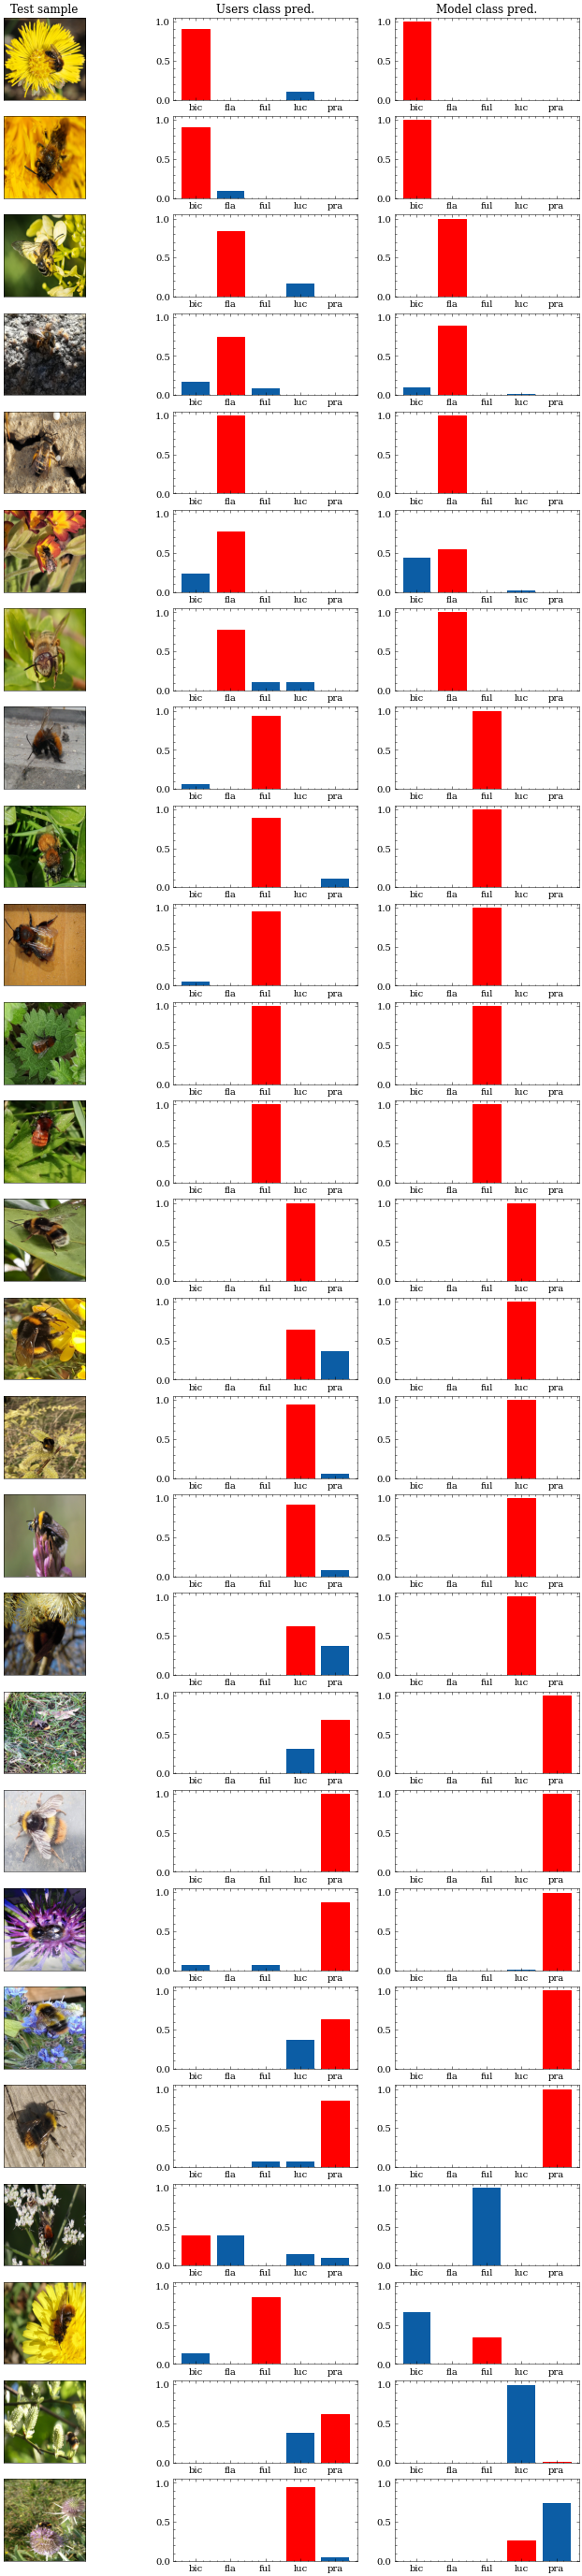

In [16]:
from PIL import Image
num_col = 3
plt.figure(figsize=(12, 50))
for i, sample in enumerate(img_user_dict):
    split_sample = sample.split('_')
    folder_name = split_sample[0] + '_' + split_sample[1] # species name for the parent folder
    cls = split_sample[0] + ' ' # species name for true class index (B. terrestris is labeled B. lucorum)
    if split_sample[1] == 'terrestris': cls += 'lucorum'
    else: cls += split_sample[1]
    y_true = np.where(classes == cls)[0][0] # index of the true class
    raw_file = '../data/Wildbienen/Bees/' + folder_name + '/' + sample
    im = np.asarray( Image.open(raw_file).resize((224, 224)) )
    plt.subplot(len(img_user_dict), num_col, num_col*i+1)
    plt.imshow(im); plt.xticks([]); plt.yticks([])
    if i == 0: plt.title('Test sample')

    plt.subplot(len(img_user_dict), num_col, num_col*i+2)
    barlist = plt.bar(np.arange(len(classes)), img_user_dict[sample])
    barlist[y_true].set_color('r') # mark bar for the true species
    plt.xticks(np.arange(len(classes)), ['bic', 'fla', 'ful', 'luc', 'pra'])
    plt.ylim([0.0, 1.05])
    if i == 0: plt.title('Users class pred.')

    plt.subplot(len(img_user_dict), num_col, num_col*i+3)
    barlist = plt.bar(np.arange(len(classes)), img_softmax_dict[sample])
    barlist[y_true].set_color('r')
    plt.xticks(np.arange(len(classes)), ['bic', 'fla', 'ful', 'luc', 'pra'])
    plt.ylim([0.0, 1.05])
    if i == 0: plt.title('Model class pred.')
plt.show()

In [10]:
group = 'XAI'
preds_task2 = stats[group][ stats[group]['task'] == 'response_pred' ]
preds_task2

,success,timeout,failed_images,failed_audio,failed_video,trial_type,trial_index,time_elapsed,internal_node_id,run_id,...,rt,stimulus,response,task,correct_response,correct,pred_class,pred_concept,question_order,fbclid
231,NaN,NaN,NaN,NaN,NaN,image-button-response,26,272986,0.0-6.0-1.0,108,...,20992.0,img/Andrena_bicolor_70836009_4.jpg,0,response_pred,Andrena bicolor,True,Andrena bicolor,YES YES NO,NaN,PAAaYvTTQZK3jpury1Z68Iz4xVf_MkdqnDH7lX7w0Iu3UM...
233,NaN,NaN,NaN,NaN,NaN,image-button-response,28,280906,0.0-6.0-1.1,108,...,7114.0,img/Bombus_pratorum_58000679_1.jpg,4,response_pred,Bombus pratorum,True,Bombus pratorum,NO YES YES,NaN,PAAaYvTTQZK3jpury1Z68Iz4xVf_MkdqnDH7lX7w0Iu3UM...
235,NaN,NaN,NaN,NaN,NaN,image-button-response,30,300384,0.0-6.0-1.2,108,...,18927.0,img/Andrena_fulva_76966123_1.jpg,2,response_pred,Andrena fulva,True,Andrena bicolor,YES YES NO,NaN,PAAaYvTTQZK3jpury1Z68Iz4xVf_MkdqnDH7lX7w0Iu3UM...
237,NaN,NaN,NaN,NaN,NaN,image-button-response,32,308799,0.0-6.0-1.3,108,...,7607.0,img/Andrena_fulva_78200707_1.jpg,2,response_pred,Andrena fulva,True,Andrena fulva,NO YES NO,NaN,PAAaYvTTQZK3jpury1Z68Iz4xVf_MkdqnDH7lX7w0Iu3UM...
239,NaN,NaN,NaN,NaN,NaN,image-button-response,34,316274,0.0-6.0-1.4,108,...,6916.0,img/Bombus_terrestris_72678063_1.jpg,3,response_pred,Bombus lucorum,True,Bombus lucorum,NO NO YES,NaN,PAAaYvTTQZK3jpury1Z68Iz4xVf_MkdqnDH7lX7w0Iu3UM...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5240,NaN,NaN,NaN,NaN,NaN,image-button-response,36,531128,0.0-6.0-1.5,93,...,11894.0,img/Andrena_fulva_78200707_1.jpg,2,response_pred,Andrena fulva,True,Andrena fulva,NO YES NO,NaN,NaN
5242,NaN,NaN,NaN,NaN,NaN,image-button-response,38,543121,0.0-6.0-1.6,93,...,11719.0,img/Andrena_fulva_77876860_3.jpg,2,response_pred,Andrena fulva,True,Andrena fulva,NO YES NO,NaN,NaN
5244,NaN,NaN,NaN,NaN,NaN,image-button-response,40,562133,0.0-6.0-1.7,93,...,18489.0,img/Andrena_flavipes_71664833_1.jpg,1,response_pred,Andrena flavipes,True,Andrena flavipes,YES NO NO,NaN,NaN
5246,NaN,NaN,NaN,NaN,NaN,image-button-response,42,578545,0.0-6.0-1.8,93,...,15638.0,img/Bombus_terrestris_72770462_2.jpg,3,response_pred,Bombus lucorum,True,Bombus lucorum,NO NO YES,NaN,NaN


In [11]:
img_user_dict = {}
for file_task2 in pool_task2:
    curr_preds = preds_task2[ preds_task2['stimulus'].replace('img/', '', regex=True) == file_task2 ]
    user_probs = curr_preds['response'].value_counts(normalize=True)
    img_user_dict[file_task2] = np.zeros(len(classes))
    for ind in user_probs.index.to_list():
        img_user_dict[file_task2][int(ind)] = user_probs[ind]
img_user_dict

{'Andrena_bicolor_2799379_1.jpg': array([0.9, 0. , 0. , 0.1, 0. ]),
 'Andrena_bicolor_70836009_4.jpg': array([0.90909091, 0.09090909, 0.        , 0.        , 0.        ]),
 'Andrena_flavipes_70667186_1.jpg': array([0.        , 0.83333333, 0.        , 0.16666667, 0.        ]),
 'Andrena_flavipes_71664833_1.jpg': array([0.16666667, 0.75      , 0.08333333, 0.        , 0.        ]),
 'Andrena_flavipes_73411496_1.jpg': array([0., 1., 0., 0., 0.]),
 'Andrena_flavipes_74766389_2.jpg': array([0.23076923, 0.76923077, 0.        , 0.        , 0.        ]),
 'Andrena_flavipes_77801499_2.jpg': array([0.        , 0.77777778, 0.11111111, 0.11111111, 0.        ]),
 'Andrena_fulva_77615356_2.jpg': array([0.06666667, 0.        , 0.93333333, 0.        , 0.        ]),
 'Andrena_fulva_77876860_3.jpg': array([0.        , 0.        , 0.88888889, 0.        , 0.11111111]),
 'Andrena_fulva_78200707_1.jpg': array([0.05263158, 0.        , 0.94736842, 0.        , 0.        ]),
 'Andrena_fulva_78437226_1.jpg': arra

In [12]:
# Load concept predictions for every pool sample
knn_preds = np.load("./beexplainable/metafiles/Bees/masked/pool_jspsych/knn_probs.npy")
knn_preds

array([[0. , 0.1, 0.9],
       [0.1, 0. , 0.9],
       [0. , 0.1, 0.9],
       [0. , 0.1, 0.9],
       [0.1, 0.1, 0.8],
       [0.1, 0.1, 0.8],
       [0. , 0.1, 0.9],
       [0. , 0.1, 0.9],
       [0.1, 0.1, 0.8],
       [0. , 0.1, 0.9],
       [0. , 0.1, 0.9],
       [0. , 0.1, 0.9],
       [0.2, 0.1, 0.7],
       [0. , 0.1, 0.9],
       [0. , 0.1, 0.9],
       [0.1, 0.2, 0.7],
       [0.1, 0.1, 0.8],
       [0.1, 0.2, 0.7],
       [0.1, 0.2, 0.7],
       [0.1, 0.2, 0.7],
       [0.1, 0. , 0.9],
       [0.1, 0. , 0.9],
       [0.1, 0. , 0.9],
       [0.1, 0.2, 0.7],
       [0.1, 0.2, 0.7],
       [0. , 0.1, 0.9],
       [0.1, 0. , 0.9],
       [0. , 0.1, 0.9],
       [0.1, 0. , 0.9],
       [0. , 0.1, 0.9],
       [0. , 0.1, 0.9],
       [0.1, 0. , 0.9],
       [0.6, 0. , 0.4],
       [0.8, 0. , 0.2],
       [0.7, 0. , 0.3],
       [0.7, 0.1, 0.2],
       [0.7, 0. , 0.3],
       [0.7, 0. , 0.3],
       [0.8, 0. , 0.2],
       [0.4, 0. , 0.6],
       [0.7, 0. , 0.3],
       [0.7, 0. 

In [13]:
img_knn_dict = dict(zip(file_names, knn_preds))
img_knn_dict

{'Andrena_bicolor_2799379_1.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_39411385_1.jpg': array([0.1, 0. , 0.9]),
 'Andrena_bicolor_39748872_3.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_40186737_3.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_42078638_3.jpg': array([0.1, 0.1, 0.8]),
 'Andrena_bicolor_44969462_15.jpg': array([0.1, 0.1, 0.8]),
 'Andrena_bicolor_44969462_2.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_70513296_3.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_70615494_2.jpg': array([0.1, 0.1, 0.8]),
 'Andrena_bicolor_70744142_2.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_70836009_2.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_70836009_4.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_71944410_2.jpg': array([0.2, 0.1, 0.7]),
 'Andrena_bicolor_72391501_2.jpg': array([0. , 0.1, 0.9]),
 'Andrena_bicolor_97033019_1.jpg': array([0. , 0.1, 0.9]),
 'Andrena_flavipes_28862388_1.jpg': array([0.1, 0.2, 0.7]),
 'Andrena_flavipes_33657115_1.jpg': array([0.1, 0.1, 0.

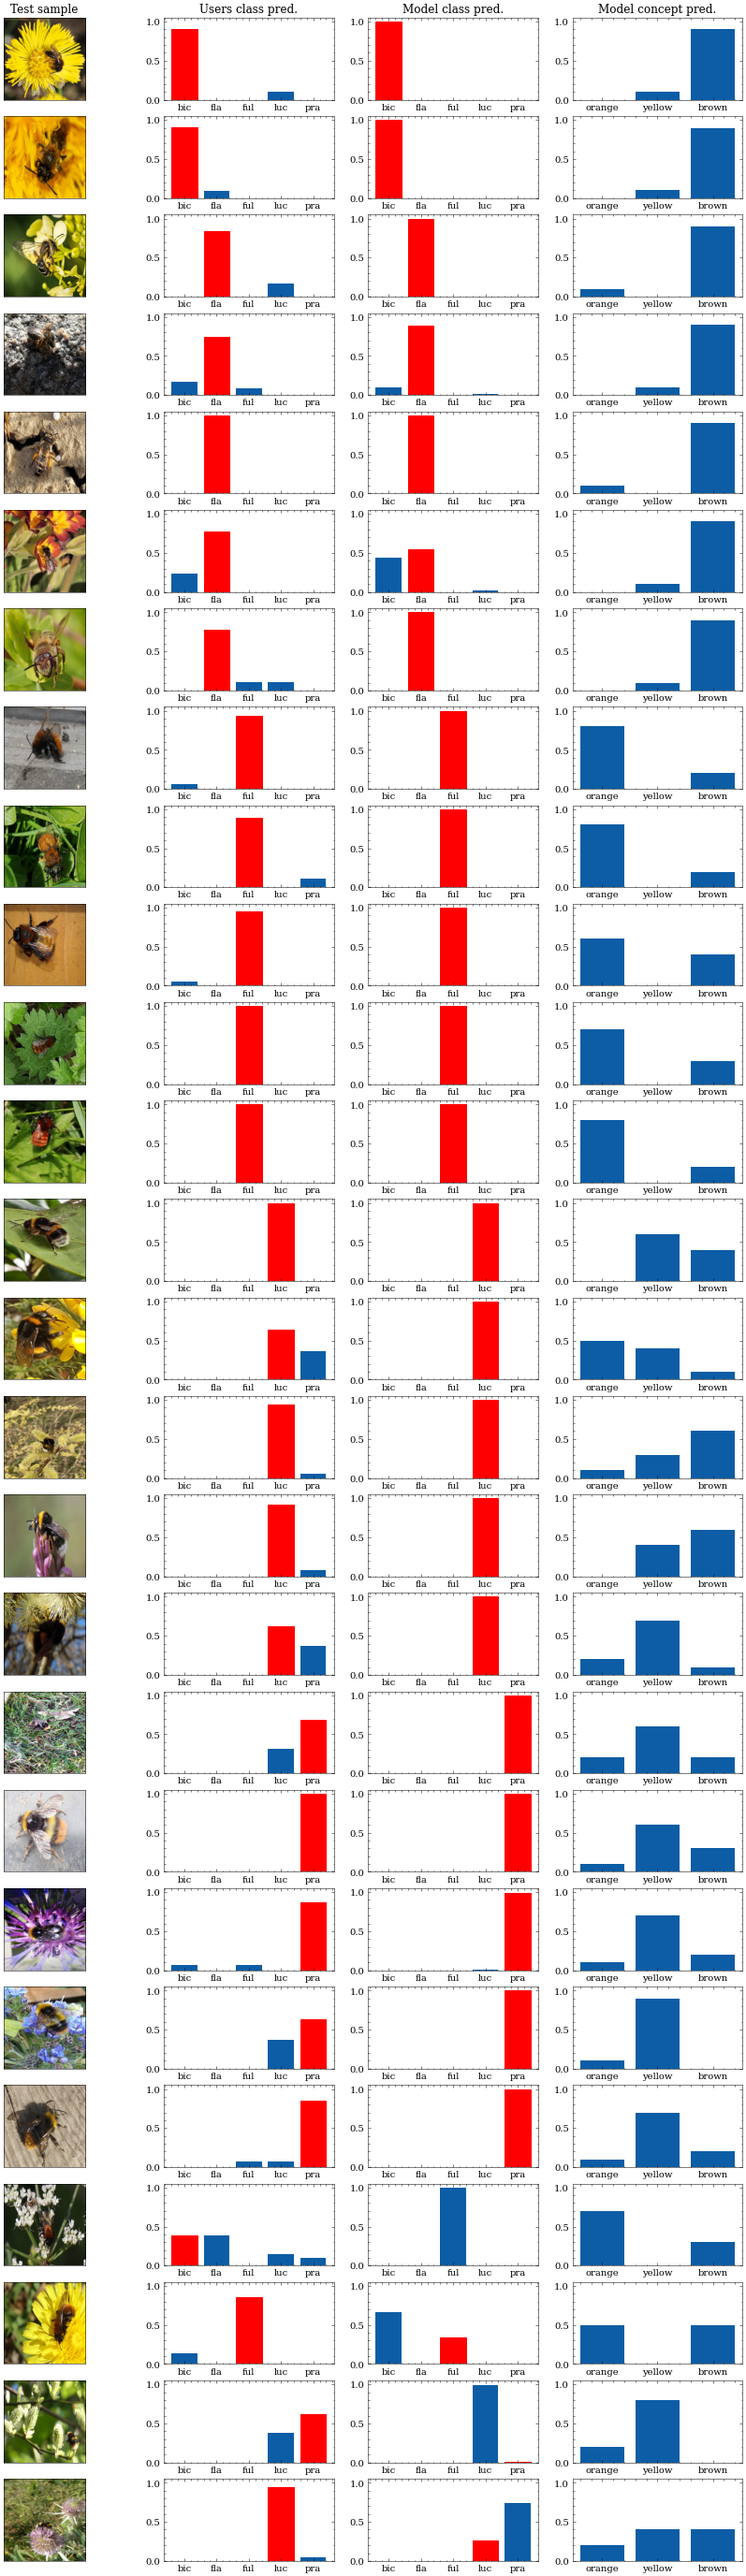

In [18]:
num_col = 4
plt.figure(figsize=(15, 50))
for i, sample in enumerate(img_user_dict):
    split_sample = sample.split('_')
    folder_name = split_sample[0] + '_' + split_sample[1] # species name for the parent folder
    cls = split_sample[0] + ' ' # species name for true class index (B. terrestris is labeled B. lucorum)
    if split_sample[1] == 'terrestris': cls += 'lucorum'
    else: cls += split_sample[1]
    y_true = np.where(classes == cls)[0][0] # index of the true class
    raw_file = '../data/Wildbienen/Bees/' + folder_name + '/' + sample
    im = np.asarray( Image.open(raw_file).resize((224, 224)) )
    plt.subplot(len(img_user_dict), num_col, num_col*i+1)
    plt.imshow(im); plt.xticks([]); plt.yticks([])
    if i == 0: plt.title('Test sample')

    plt.subplot(len(img_user_dict), num_col, num_col*i+2)
    barlist = plt.bar(np.arange(len(classes)), img_user_dict[sample])
    barlist[y_true].set_color('r') # mark bar for the true species
    plt.xticks(np.arange(len(classes)), ['bic', 'fla', 'ful', 'luc', 'pra'])
    plt.ylim([0.0, 1.05])
    if i == 0: plt.title('Users class pred.')

    plt.subplot(len(img_user_dict), num_col, num_col*i+3)
    barlist = plt.bar(np.arange(len(classes)), img_softmax_dict[sample])
    barlist[y_true].set_color('r')
    plt.xticks(np.arange(len(classes)), ['bic', 'fla', 'ful', 'luc', 'pra'])
    plt.ylim([0.0, 1.05])
    if i == 0: plt.title('Model class pred.')

    plt.subplot(len(img_user_dict), num_col, num_col*i+4)
    plt.bar(np.arange(3), img_knn_dict[sample])
    plt.xticks(np.arange(3), ['orange', 'yellow', 'brown'])
    plt.ylim([0.0, 1.05])
    if i == 0: plt.title('Model concept pred.')
plt.show()